# _**Exploratory Data Analysis of Concrete Defect Point Clouds**_

> This notebook presents the initial exploration of the concrete point-cloud dataset used in this research. The aim is to understand the dataset structure, examine the available point-cloud files, and assess the quality and characteristics of the data before implementing the PointNet-based models.

>The analysis will cover file inspection, point distribution, coordinate ranges, data consistency, and visualisation of selected point-cloud segments

In [6]:
# importing libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [7]:
# data directory
data_dir = Path('../data/SNEPointNet2/data')

# Get all point-cloud text files
point_files = sorted(data_dir.glob("*.txt"))

# Display the results
print("Dataset directory:", data_dir.resolve())
print("Total number of point-cloud files:", len(point_files))

print("\nFirst five files:")
for file in point_files[:5]:
    print(file.name)

Dataset directory: /mnt/c/Users/Danhaya/ArewaDS/pointnet-concrete-defect-robustness/data/SNEPointNet2/data
Total number of point-cloud files: 102

First five files:
part (1).txt
part (10).txt
part (100).txt
part (101).txt
part (102).txt


Let me examines a sample point-cloud file to understand its structure and numerical format. This may helps in the future analysis.

In [8]:
# first point-cloud file
sample_file = point_files[0]

# Display its name and size
print("Selected file:", sample_file.name)
print("File size:", round(sample_file.stat().st_size / 1024, 2), "KB")

# Read and display the first five lines
with open(sample_file, "r") as file:
    for i in range(5):
        print(file.readline().strip())

Selected file: part (1).txt
File size: 22499.25 KB
28.755 6.229 10.433 132 117 76 0.008867 -0.999960 -0.000985
28.754 6.229 10.519 138 126 88 0.008884 -0.999956 -0.002961
28.736 6.229 10.544 136 123 91 0.004907 -0.999987 0.000981
28.754 6.229 10.474 128 110 70 0.012857 -0.999917 0.000989
28.754 6.229 10.412 136 122 87 0.002944 -0.999995 -0.000981


In [9]:
# Load one point-cloud file
point_cloud = np.loadtxt(sample_file)

# Display basic information
print("Data shape:", point_cloud.shape)
print("Data type:", point_cloud.dtype)

print("\nFirst five points:")
print(point_cloud[:5])

Data shape: (384346, 9)
Data type: float64

First five points:
[[ 2.87550e+01  6.22900e+00  1.04330e+01  1.32000e+02  1.17000e+02
   7.60000e+01  8.86700e-03 -9.99960e-01 -9.85000e-04]
 [ 2.87540e+01  6.22900e+00  1.05190e+01  1.38000e+02  1.26000e+02
   8.80000e+01  8.88400e-03 -9.99956e-01 -2.96100e-03]
 [ 2.87360e+01  6.22900e+00  1.05440e+01  1.36000e+02  1.23000e+02
   9.10000e+01  4.90700e-03 -9.99987e-01  9.81000e-04]
 [ 2.87540e+01  6.22900e+00  1.04740e+01  1.28000e+02  1.10000e+02
   7.00000e+01  1.28570e-02 -9.99917e-01  9.89000e-04]
 [ 2.87540e+01  6.22900e+00  1.04120e+01  1.36000e+02  1.22000e+02
   8.70000e+01  2.94400e-03 -9.99995e-01 -9.81000e-04]]


_The sample file contains 384,346 points, with nine numerical features per point. These features appear to represent 3D coordinates, RGB colour values, and surface normal components. The data was successfully loaded into NumPy as a two-dimensional array of type `float64`._

This step examines the number of points contained in each point-cloud file. Comparing the files will help us understand variations in dataset size and determine whether the point clouds have consistent sampling characteristics.

In [10]:
# Count the number of points in each file
point_counts = []

for file in point_files:
    with open(file, "r") as f:
        count = sum(1 for line in f if line.strip())

    point_counts.append({
        "file": file.name,
        "number_of_points": count
    })

# Convert the results into a DataFrame
point_distribution = pd.DataFrame(point_counts)

# Display the first five results
point_distribution.head()

,file,number_of_points
0,part (1).txt,384346
1,part (10).txt,346994
2,part (100).txt,380314
3,part (101).txt,423704
4,part (102).txt,342697


This variation indicates differences in the number of spatial measurements recorded for each concrete segment, which may influence point-cloud sampling and model input preparation.

In [11]:
# Calculate descriptive statistics for point counts
point_distribution["number_of_points"].describe()

count       102.000000
mean     261747.931373
std       96566.489757
min       79719.000000
25%      189460.750000
50%      260242.500000
75%      337164.750000
max      500720.000000
Name: number_of_points, dtype: float64

_The dataset contains 102 point-cloud files, with an average of approximately 261,748 points per file. The point counts range from 79,719 to 500,720, indicating considerable variation in the size of the point clouds. The mean and median are relatively close, suggesting a reasonably centred distribution. These variations are important when preparing the dataset for PointNet, as a consistent number of input points may be required during model training_.

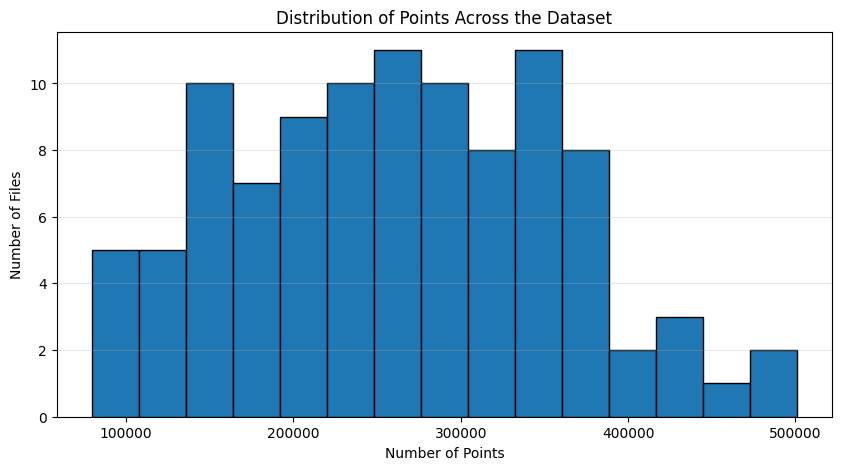

In [12]:

plt.figure(figsize=(10, 5))

plt.hist(
    point_distribution["number_of_points"],
    bins=15,
    edgecolor="black"
)

plt.xlabel("Number of Points")
plt.ylabel("Number of Files")
plt.title("Distribution of Points Across the Dataset")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [13]:
# Calculate descriptive statistics for all nine attributes
attribute_summary = pd.DataFrame({
    "Minimum": np.min(point_cloud, axis=0),
    "Maximum": np.max(point_cloud, axis=0),
    "Mean": np.mean(point_cloud, axis=0),
    "Standard Deviation": np.std(point_cloud, axis=0)
}, index=[
    "X", "Y", "Z",
    "Red", "Green", "Blue",
    "Normal_X", "Normal_Y", "Normal_Z"
])

attribute_summary

,Minimum,Maximum,Mean,Standard Deviation
X,26.075000,29.161000,27.608900,0.899278
Y,6.157000,6.236000,6.217785,0.007855
Z,7.966000,10.816000,9.379767,0.819457
Red,26.000000,255.000000,166.484129,28.148254
Green,26.000000,236.000000,150.218139,25.389937
Blue,19.000000,215.000000,124.396398,27.467708
Normal_X,-0.999999,0.999852,-0.019787,0.124392
Normal_Y,-0.999999,0.999948,-0.947110,0.291970
Normal_Z,-0.990232,0.975427,0.001618,0.043237


_The point-cloud file contains nine attributes per point: three spatial coordinates (X, Y, Z), three RGB colour components, and three surface normal components. The spatial coordinates describe the 3D positions of points, while the RGB values provide information about surface appearance. The surface normals represent the local geometric orientation of the concrete surface. These combined attributes provide spatial, colour, and geometric information for subsequent semantic segmentation._

In [14]:
# Extract the three surface normal components
normal_vectors = point_cloud[:, 6:9]

# Calculate the magnitude of each normal vector
normal_magnitudes = np.linalg.norm(normal_vectors, axis=1)

# Summarise the normal magnitudes
print("Normal vector magnitude statistics:")
print(pd.Series(normal_magnitudes).describe())

# Check the proportion of approximately unit-length normals
unit_normals = np.isclose(normal_magnitudes, 1.0, atol=0.01)

print("\nPercentage of approximately unit-length normals:",
      round(unit_normals.mean() * 100, 2), "%")

Normal vector magnitude statistics:
count    3.843460e+05
mean     1.000000e+00
std      2.935459e-07
min      9.999992e-01
25%      9.999997e-01
50%      1.000000e+00
75%      1.000000e+00
max      1.000001e+00
dtype: float64

Percentage of approximately unit-length normals: 100.0 %


_The magnitude of the surface normal vectors was calculated to verify their normalization. The results show a mean magnitude of 1.000000, with minimum and maximum values of 0.9999992 and 1.000001, respectively. This confirms that the surface normal vectors are already normalized to approximately unit length._ 

In [15]:
# Inspect the structure of every point-cloud file
file_structure = []

for file in point_files:
    try:
        cloud = np.loadtxt(file, ndmin=2)

        file_structure.append({
            "file": file.name,
            "number_of_points": cloud.shape[0],
            "number_of_attributes": cloud.shape[1],
            "data_type": str(cloud.dtype),
            "status": "Valid"
        })

    except (ValueError, OSError) as error:
        file_structure.append({
            "file": file.name,
            "number_of_points": None,
            "number_of_attributes": None,
            "data_type": None,
            "status": str(error)
        })

# Convert results into a DataFrame
file_structure_df = pd.DataFrame(file_structure)

# Display the first five results
file_structure_df.head()

,file,number_of_points,number_of_attributes,data_type,status
0,part (1).txt,384346,9,float64,Valid
1,part (10).txt,346994,9,float64,Valid
2,part (100).txt,380314,9,float64,Valid
3,part (101).txt,423704,9,float64,Valid
4,part (102).txt,342697,9,float64,Valid


In [16]:
# Examine the consistency of attributes and data types
print("Number of files examined:", len(file_structure_df))

print("\nAttribute counts:")
print(file_structure_df["number_of_attributes"].value_counts(dropna=False))

print("\nData types:")
print(file_structure_df["data_type"].value_counts(dropna=False))

print("\nFile status:")
print(file_structure_df["status"].value_counts())

Number of files examined: 102

Attribute counts:
number_of_attributes
9    102
Name: count, dtype: int64

Data types:
data_type
float64    102
Name: count, dtype: int64

File status:
status
Valid    102
Name: count, dtype: int64


_All 102 point-cloud files contain nine attributes per point and are consistently stored as float64 numerical arrays. No file-reading errors or structural inconsistencies were identified, although the number of points varies across files._